<a href="https://colab.research.google.com/github/Chinta-Rohith/Generative-AI-Lab/blob/main/EXP11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
os.environ["USE_TF"] = "0"
os.environ["USE_FLAX"] = "0"

!pip install -q transformers==4.51.3 huggingface-hub==0.30.2 tokenizers==0.21.1

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.30.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.30.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.30.2 which is incompatible.
gradio 6.31.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


Running on CPU


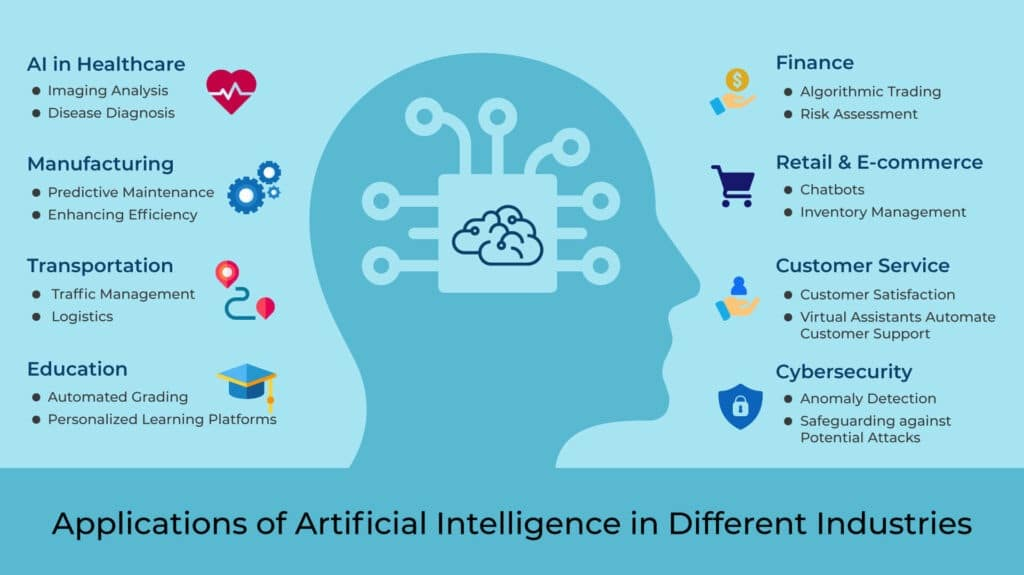

Loading processor...


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Loading model...


model.safetensors:   0%|          | 0.00/513M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/136 [00:00<?, ?B/s]

Model loaded successfully!

===== SMART CLASSROOM AI AGENT =====

1. Ask a question
2. Summarize lecture
3. Describe image
4. Exit
Enter choice: 3

IMAGE DESCRIPTION:
 This is an infographic titled "Applications of Artificial Intelligence in Different Industries". The title is in bold blue text at the top. The text in the center of the slide is about "AI in Healthcare". The text in the center of the slide is about "Disease Diagnosis". The text in the center of the slide is about "Manufacturing". The text in the center of the slide is about "

1. Ask a question
2. Summarize lecture
3. Describe image
4. Exit
Enter choice: 1
Enter your question: Explain AI in transporattion

AI is processing...

ANSWER:
 AI in transportation, logistics, logistics, logistics, logistics, logistics, logistics, logistics, logistics, logistics, logistics, logistics, logistics, logistics, logistics, logistics, logistics, logistics, logistics, logistics, logistics, logistics, logistics, logistics, logistics, log

In [ ]:
# ============================================================
# MULTIMODAL AI AGENT - SMART CLASSROOM ASSISTANT
# CPU | NO API KEY | YOUR IMAGE
# ============================================================

import os
os.environ["USE_TF"] = "0"
os.environ["USE_FLAX"] = "0"

import torch
from PIL import Image
from transformers import AutoProcessor, AutoModelForVision2Seq

# Configuration
MODEL_NAME = "HuggingFaceTB/SmolVLM-256M-Instruct"
IMAGE_PATH = "/content/test.jpg"
device = "cpu"

print("Running on CPU")

# Load image
image = Image.open(IMAGE_PATH).convert("RGB")
display(image)

# Load processor
print("Loading processor...")
processor = AutoProcessor.from_pretrained(MODEL_NAME)

# Load model
print("Loading model...")
model = AutoModelForVision2Seq.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float32
)

model.to(device)
model.eval()

print("Model loaded successfully!")

# Multimodal processing function
def ask_classroom(question):

    messages = [
        {
            "role": "user",
            "content": [
                {"type": "image", "image": image},
                {
                    "type": "text",
                    "text": (
                        "You are a Smart Classroom Assistant. "
                        "Analyze this lecture slide and answer "
                        "the question in simple language.\n"
                        "Question: " + question
                    )
                }
            ]
        }
    ]

    inputs = processor.apply_chat_template(
        messages,
        add_generation_prompt=True,
        tokenize=True,
        return_dict=True,
        return_tensors="pt"
    )

    inputs = inputs.to(device)

    with torch.no_grad():
        output = model.generate(
            **inputs,
            max_new_tokens=80,
            do_sample=False
        )

    # Extract only the generated answer
    prompt_len = inputs["input_ids"].shape[1]
    answer_tokens = output[:, prompt_len:]

    answer = processor.batch_decode(
        answer_tokens,
        skip_special_tokens=True
    )[0]

    return answer.strip()


# Smart Classroom Agent
class SmartClassroomAgent:

    def answer_question(self, question):
        return ask_classroom(question)

    def summarize(self):
        return ask_classroom(
            "Summarize this slide, covering the main topic "
            "and all the AI applications in the different "
            "industries shown."
        )

    def describe(self):
        return ask_classroom(
            "Describe the complete slide, including its title, "
            "all text, and the applications listed."
        )


# Initialize agent
agent = SmartClassroomAgent()

print("\n===== SMART CLASSROOM AI AGENT =====")

# Interactive testing
while True:

    print("\n1. Ask a question")
    print("2. Summarize lecture")
    print("3. Describe image")
    print("4. Exit")

    choice = input("Enter choice: ")

    if choice == "1":
        question = input("Enter your question: ")
        print("\nAI is processing...")
        print("\nANSWER:\n", agent.answer_question(question))

    elif choice == "2":
        print("\nGenerating summary...")
        print("\nSUMMARY:\n", agent.summarize())

    elif choice == "3":
        print("\nIMAGE DESCRIPTION:\n", agent.describe())

    elif choice == "4":
        print("Agent terminated.")
        break

    else:
        print("Invalid choice. Enter 1-4.")